# Étape 1.0 — Présentation des données

> **Énoncé (partie 1)** : présenter les variables disponibles et préciser leur nature ; identifier les variables cibles de la segmentation et des analyses de fréquence et de gravité ; réaliser une analyse descriptive ; présenter un tableau récapitulatif de la base.

Ce notebook reprend le script `etape_1_0_presentation.py` : mêmes calculs, mêmes résultats, enregistrés dans `resultats/`. Les décisions et l'interprétation des résultats sont détaillées dans [README.md](README.md) (version LaTeX : `README.tex`).

**Contenu de l'étape :**


- présente les 73 variables et leur nature (quantitative / qualitative) ;
- identifie les variables cibles (segmentation, fréquence, sévérité) ;
- réalise l'analyse descriptive des données brutes ;
- produit le tableau récapitulatif de la base.


## Préparation

Bibliothèques, module commun du projet, dossier de résultats et journal.

In [1]:
import re
import sys
from pathlib import Path

# Le notebook s'exécute dans le dossier de l'étape : on remonte jusqu'à la racine du projet
RACINE_PROJET = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "commun" / "outils.py").exists())
sys.path.insert(0, str(RACINE_PROJET))

import numpy as np
import pandas as pd

from commun import outils as o

RES = o.dossier_resultats("1.0")
log = o.Journal(RES, "Étape 1.0 — Présentation des données")
plt = o.style_graphique()

brut, libelles = o.charger_donnees_brutes()
n, p = brut.shape
log(f"Fichier : {o.FICHIER_BRUT.name} — feuille DataUsed — {n} lignes × {p} colonnes");

# Étape 1.0 — Présentation des données


Fichier : InsuranceData.xlsx — feuille DataUsed — 4076 lignes × 73 colonnes


## 1. Dictionnaire des variables

In [2]:
log.section("1. Dictionnaire des variables")


def stockage(serie: pd.Series) -> str:
    if pd.api.types.is_numeric_dtype(serie):
        return "nombre"
    nombres = serie.dropna().astype(str).str.strip().str.fullmatch(r"\d+([.,]\d+)?")
    return "texte (nombres saisis en texte)" if nombres.mean() > 0.5 else "texte"


def exemples(serie: pd.Series, k: int = 3) -> str:
    vc = serie.dropna().astype(str).map(lambda s: " ".join(s.split())).value_counts()
    return " | ".join(v[:35] for v in vc.index[:k])


dico = pd.DataFrame({
    "code": o.CODES,
    "libelle_origine": [libelles[c] for c in o.CODES],
    "bloc": [o.BLOC[c] for c in o.CODES],
    "nature": [o.NATURE[c] for c in o.CODES],
    "stockage_excel": [stockage(brut[c]) for c in o.CODES],
    "nb_valeurs_distinctes": [brut[c].nunique() for c in o.CODES],
    "pct_manquants": [100 * brut[c].isna().mean() for c in o.CODES],
    "exemples": [exemples(brut[c]) for c in o.CODES],
})
o.sauver_table(dico, RES, "dictionnaire_variables")
log.table(dico.drop(columns=["libelle_origine", "exemples"]), index=False, floatfmt=".1f")

par_nature = dico.groupby("nature").size().rename("nb_variables").to_frame()
par_bloc = dico.groupby("bloc", sort=False).agg(
    nb_variables=("code", "size"), variables=("code", lambda s: ", ".join(s)))
o.sauver_table(par_nature, RES, "variables_par_nature", index=True)
o.sauver_table(par_bloc, RES, "variables_par_bloc", index=True)
log("Variables par nature :")
log.table(par_nature)
log("Variables par bloc thématique :")
log.table(par_bloc);


## 1. Dictionnaire des variables



code,bloc,nature,stockage_excel,nb_valeurs_distinctes,pct_manquants
id,Identifiant,Identifiant,nombre,4076,0.0
sexe,Démographie,Qualitative nominale,texte,4,0.2
age,Démographie,Quantitative continue,nombre,53,0.2
fokotany,Démographie,Qualitative nominale,texte,237,0.1
lien_chef_menage,Démographie,Qualitative nominale,texte,8,0.5
statut_pro,Activité professionnelle,Qualitative nominale,texte,6,0.2
statut_matrimonial,Démographie,Qualitative nominale,texte,5,0.3
taille_menage,Ménage et logement,Quantitative discrète,nombre,18,0.1
nb_actifs_menage,Ménage et logement,Quantitative discrète,nombre,8,0.1
secteur,Activité professionnelle,Qualitative nominale,texte,103,0.4


Variables par nature :


,nb_variables
nature,
Identifiant,1
Qualitative nominale,30
Qualitative ordinale,17
Quantitative continue,17
Quantitative discrète,5
Texte libre,3


Variables par bloc thématique :


,nb_variables,variables
bloc,,
Identifiant,1,id
Démographie,6,"sexe, age, fokotany, lien_chef_menage, statut_matrimonial, niveau_etude"
Activité professionnelle,9,"statut_pro, secteur, activite_famille, anciennete_emploi, distance_travail, transport_travail, heures_jour, jours_semaine, nb_employes"
Ménage et logement,8,"taille_menage, nb_actifs_menage, activite_conjoint, statut_residence, source_eau, source_electricite, energie_cuisine, type_toilette"
Revenus et budget,6,"revenu, budget_alim, budget_sante, budget_elec, epargne, dettes"
Conditions de travail,6,"effort_physique, duree_effort, pb_sante_travail, arret_maladie, impact_travail_sante, repos_recent"
Couverture maladie,6,"couverture, mode_affiliation, type_couverture, ancienne_couverture, interet_couverture, prime_souhaitee"
État de santé,12,"maladie_chronique, chronique_categorie, chronique_detail, traitement_regulier, freq_consult_chronique, depense_medic_chronique, lunettes, valeur_lunettes, dentiste, freq_dentiste, nb_maladies_graves, renoncement_soins"
Dernier épisode de maladie,10,"date_derniere_maladie, type_maladie, douleur, jours_arret, type_recours, motif_recours, distance_soins, satisfaction, autre_recours_souhaite, benefice_autre_recours"


## 2. Variables cibles

In [3]:
log.section("2. Variables cibles")
couts_renseignes = brut[o.COUTS].notna().any(axis=1).sum()
cibles = pd.DataFrame([
    {"analyse": "Segmentation (K-means)",
     "variable_cible": "aucune (apprentissage non supervisé)",
     "role": "Les assurés sont regroupés selon leur profil (démographie, situation "
             "socio-économique, conditions de travail, état de santé). Le segment obtenu "
             "devient la variable cible de l'arbre CART (étape 2.2).",
     "observations_disponibles": n},
    {"analyse": "Fréquence des sinistres (GLM)",
     "variable_cible": "nb_maladies_graves",
     "role": "N_i = nombre de maladies graves déclarées sur 12 mois (comptage).",
     "observations_disponibles": int(brut["nb_maladies_graves"].notna().sum())},
    {"analyse": "Sévérité des sinistres (GLM)",
     "variable_cible": "cout_total = somme des coûts G.1 à G.6",
     "role": "S_i = coût du dernier épisode de maladie (consultation, hospitalisation, "
             "médicaments, déplacement, alimentation, autres), en Ariary. Construit à "
             "l'étape 1.1 après conversion du texte libre.",
     "observations_disponibles": int(couts_renseignes)},
])
o.sauver_table(cibles, RES, "variables_cibles")
log.table(cibles, index=False);


## 2. Variables cibles



analyse,variable_cible,role,observations_disponibles
Segmentation (K-means),aucune (apprentissage non supervisé),"Les assurés sont regroupés selon leur profil (démographie, situation socio-économique, conditions de travail, état de santé). Le segment obtenu devient la variable cible de l'arbre CART (étape 2.2).",4076
Fréquence des sinistres (GLM),nb_maladies_graves,N_i = nombre de maladies graves déclarées sur 12 mois (comptage).,4047
Sévérité des sinistres (GLM),cout_total = somme des coûts G.1 à G.6,"S_i = coût du dernier épisode de maladie (consultation, hospitalisation, médicaments, déplacement, alimentation, autres), en Ariary. Construit à l'étape 1.1 après conversion du texte libre.",3871


## 3. Tableau récapitulatif de la base

In [4]:
log.section("3. Tableau récapitulatif")
doublons = int(brut.drop(columns="id").duplicated().sum())
recap = pd.DataFrame([
    ("Nombre d'observations (individus)", n),
    ("Nombre de variables", p),
    ("dont identifiant", int((dico.nature == "Identifiant").sum())),
    ("dont quantitatives", int(dico.nature.str.startswith("Quantitative").sum())),
    ("dont qualitatives", int(dico.nature.str.startswith("Qualitative").sum())),
    ("dont texte libre", int((dico.nature == "Texte libre").sum())),
    ("Variables stockées en nombre dans Excel", int((dico.stockage_excel == "nombre").sum())),
    ("Variables quantitatives saisies en texte", int(((dico.stockage_excel != "nombre")
                                                     & dico.nature.str.startswith("Quantitative")).sum())),
    ("Cellules manquantes (% du total)", round(100 * brut.isna().to_numpy().mean(), 1)),
    ("Variables avec plus de 50 % de manquants", int((dico.pct_manquants > 50).sum())),
    ("Variables sans aucun manquant", int((dico.pct_manquants == 0).sum())),
    ("Lignes en double (hors identifiant)", doublons),
    ("Identifiant unique", "oui" if brut["id"].is_unique else "non"),
], columns=["caracteristique", "valeur"])
o.sauver_table(recap, RES, "tableau_recapitulatif")
log.table(recap, index=False);


## 3. Tableau récapitulatif



caracteristique,valeur
Nombre d'observations (individus),4076
Nombre de variables,73
dont identifiant,1
dont quantitatives,22
dont qualitatives,47
dont texte libre,3
Variables stockées en nombre dans Excel,9
Variables quantitatives saisies en texte,14
Cellules manquantes (% du total),15.70
Variables avec plus de 50 % de manquants,10


## 4. Statistiques descriptives — variables quantitatives stockées en nombre

In [5]:
log.section("4. Statistiques descriptives des variables quantitatives (données brutes)")
quanti = [c for c in o.CODES if o.NATURE[c].startswith("Quantitative")
          and pd.api.types.is_numeric_dtype(brut[c])]
desc = brut[quanti].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc.insert(1, "manquants", n - desc["count"])
desc["asymetrie"] = brut[quanti].skew()
desc = desc.rename(columns={"count": "n", "mean": "moyenne", "std": "ecart_type", "min": "min",
                            "1%": "P1", "25%": "Q1", "50%": "mediane", "75%": "Q3",
                            "99%": "P99", "max": "max"})
o.sauver_table(desc, RES, "stats_quantitatives", index=True)
log.table(desc, floatfmt=",.1f");


## 4. Statistiques descriptives des variables quantitatives (données brutes)



,n,manquants,moyenne,ecart_type,min,P1,Q1,mediane,Q3,P99,max,asymetrie
age,"4,066.0",10.0,37.8,11.5,3.0,18.0,28.0,37.0,46.0,59.0,112.0,0.3
taille_menage,"4,071.0",5.0,4.5,1.9,-6.0,1.0,3.0,4.0,5.0,10.0,30.0,2.8
nb_actifs_menage,"4,070.0",6.0,1.9,0.9,0.0,0.0,1.0,2.0,2.0,5.0,7.0,0.9
budget_alim,"3,963.0",113.0,264.1,"5,670.4",0.0,0.0,45.0,50.0,70.0,100.0,"250,000.0",35.2
budget_sante,"3,870.0",206.0,71.1,"1,559.2",0.0,0.0,0.0,10.0,10.0,31.5,"70,000.0",34.3
budget_elec,"3,873.0",203.0,27.2,480.9,0.0,0.0,1.0,5.0,10.0,25.0,"17,000.0",27.0
prime_souhaitee,"3,938.0",138.0,"8,310.3","8,892.6","-5,000.0",0.0,"2,000.0","5,000.0","10,000.0","30,000.0","200,000.0",4.2
nb_maladies_graves,"4,047.0",29.0,2.2,13.8,-1.0,0.0,1.0,1.0,2.0,10.0,365.0,24.2


In [6]:
# Quantitatives saisies en texte : part de nombres « propres »
texte_quanti = [c for c in o.CODES if o.NATURE[c].startswith("Quantitative")
                and not pd.api.types.is_numeric_dtype(brut[c])]
lignes = []
for c in texte_quanti:
    s = brut[c].dropna().astype(str).str.strip()
    propres = s.str.fullmatch(r"\d+([.,]\d+)?")
    lignes.append({"variable": c, "renseignees": len(s), "nombres_purs": int(propres.sum()),
                   "pct_nombres_purs": 100 * propres.mean(),
                   "exemples_non_numeriques": " | ".join(s[~propres].value_counts().index[:4])})
saisie_texte = pd.DataFrame(lignes)
o.sauver_table(saisie_texte, RES, "quantitatives_saisies_en_texte")
log("Variables quantitatives saisies en texte (converties à l'étape 1.1) :")
log.table(saisie_texte, index=False, floatfmt=".1f");

Variables quantitatives saisies en texte (converties à l'étape 1.1) :


variable,renseignees,nombres_purs,pct_nombres_purs,exemples_non_numeriques
anciennete_emploi,4061,2986,73.5,2ans | 5ans | 10ans | 20ans
distance_travail,4046,2175,53.8,1km | 2km | O | 3km
heures_jour,4065,3305,81.3,8h | 10h | 6h | Arakaraka
jours_semaine,4064,3287,80.9,6j | 6/7 | 7/7 | 7j
nb_employes,3401,2716,79.9,O | Tsy mampiasa | Kifanomba | Izy roa ihany
depense_medic_chronique,53,46,86.8,tsy nisy | Tsy tadidiny koa fa efa taloha izy no azon'izany aretina izany | 20 600 | 60000 isambolana
jours_arret,3907,2845,72.8,Herinandro | 2j | 3j | Niasa hiany
distance_soins,3884,2600,66.9,O | 1km | 2km | 3km
cout_consultation,3818,3185,83.4,O | Tsy nisy | 20 000 | 00 satria tsy namonjy dokotera
cout_hospitalisation,3778,3122,82.6,O | Tsy nisy | P | 5000 par jours


## 5. Distributions des variables qualitatives (données brutes)

In [7]:
log.section("5. Distributions des variables qualitatives (données brutes)")
quali = [c for c in o.CODES if o.NATURE[c].startswith("Qualitative")]
frequences, resume_quali = [], []
for c in quali:
    s = brut[c].map(lambda v: np.nan if pd.isna(v) else " ".join(str(v).split()))
    _, multiples = o.premiere_modalite(brut[c]) if c != "fokotany" else (None, pd.Series(False))
    vc = s.value_counts(dropna=False)
    for modalite, eff in vc.items():
        frequences.append({"variable": c, "modalite": "Manquant" if pd.isna(modalite) else modalite,
                           "effectif": int(eff), "pourcentage": 100 * eff / n})
    principale = vc.drop(index=[i for i in vc.index if pd.isna(i)], errors="ignore")
    resume_quali.append({
        "variable": c, "nature": o.NATURE[c], "modalites_distinctes": int(s.nunique()),
        "cellules_reponses_multiples": int(multiples.sum()),
        "modalite_principale": str(principale.index[0])[:45] if len(principale) else "",
        "pct_modalite_principale": 100 * principale.iloc[0] / n if len(principale) else np.nan,
        "pct_manquants": 100 * s.isna().mean()})
frequences = pd.DataFrame(frequences)
resume_quali = pd.DataFrame(resume_quali)
o.sauver_table(frequences, RES, "frequences_qualitatives")
o.sauver_table(resume_quali, RES, "resume_qualitatives")
log.table(resume_quali, index=False, floatfmt=".1f");


## 5. Distributions des variables qualitatives (données brutes)



variable,nature,modalites_distinctes,cellules_reponses_multiples,modalite_principale,pct_modalite_principale,pct_manquants
sexe,Qualitative nominale,4,4,Féminin,57.3,0.2
fokotany,Qualitative nominale,196,0,Ambohibary,12.5,0.1
lien_chef_menage,Qualitative nominale,8,14,1. Chef de ménage (CM)(loham-pianakaviana),52.8,0.5
statut_pro,Qualitative nominale,6,10,2. indépendant,83.7,0.2
statut_matrimonial,Qualitative nominale,5,1,Marié,70.0,0.3
secteur,Qualitative nominale,103,355,1. Agricole,24.8,0.4
activite_conjoint,Qualitative nominale,17,37,1. Travailleur indépendant (miasa tena),33.9,30.3
niveau_etude,Qualitative ordinale,8,3,3. Collège,36.8,0.2
statut_residence,Qualitative nominale,2,0,Tompon-trano,52.1,0.1
source_eau,Qualitative nominale,9,22,2. Borne fontaine (popim-panjakana/pompy eo a,81.1,0.2


In [8]:
# Variable de fréquence : distribution complète
freq_n = brut["nb_maladies_graves"].value_counts(dropna=False).sort_index()
freq_n.index = freq_n.index.map(lambda v: "Manquant" if pd.isna(v) else int(v))
o.sauver_table(freq_n.rename("effectif").to_frame(), RES, "distribution_nb_maladies_graves", index=True)
m, v = brut["nb_maladies_graves"].mean(), brut["nb_maladies_graves"].var()
log(f"nb_maladies_graves : moyenne {m:.2f}, variance {v:.1f}, variance / moyenne {v / m:.1f}");

nb_maladies_graves : moyenne 2.25, variance 190.1, variance / moyenne 84.5


## 6. Figures

In [9]:
C = o.COULEURS
BLEU = o.SERIES[0]

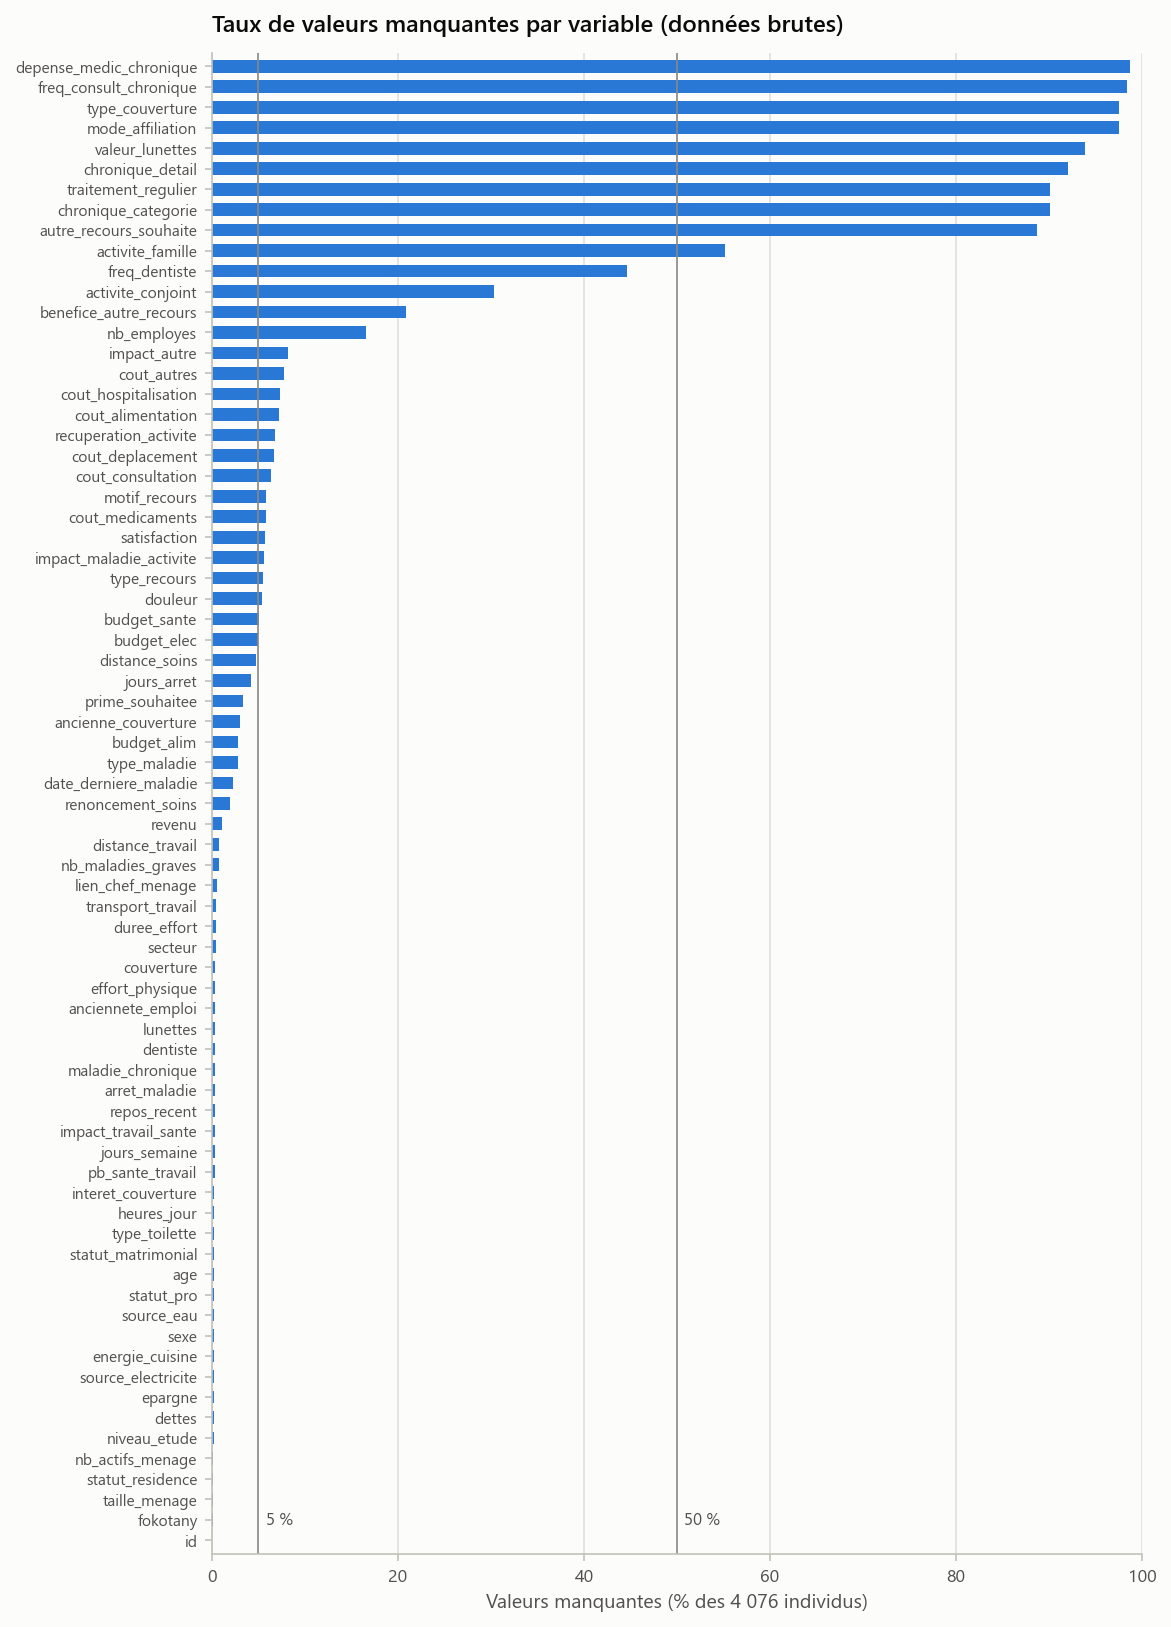

In [10]:
# 6.1 Taux de manquants par variable
d = dico.sort_values("pct_manquants")
fig, ax = plt.subplots(figsize=(8, 13))
ax.barh(d.code, d.pct_manquants, color=BLEU, height=0.62)
for seuil, texte in [(5, "5 %"), (50, "50 %")]:
    ax.axvline(seuil, color=C["attenue"], lw=0.8)
    ax.text(seuil + 0.8, 1, texte, color=C["encre2"], fontsize=8, va="center")
ax.set_xlim(0, 100)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Valeurs manquantes (% des 4 076 individus)")
ax.set_title("Taux de valeurs manquantes par variable (données brutes)")
ax.tick_params(axis="y", labelsize=7.5)
ax.margins(y=0.005)
o.sauver_figure(fig, RES, "manquants_par_variable");

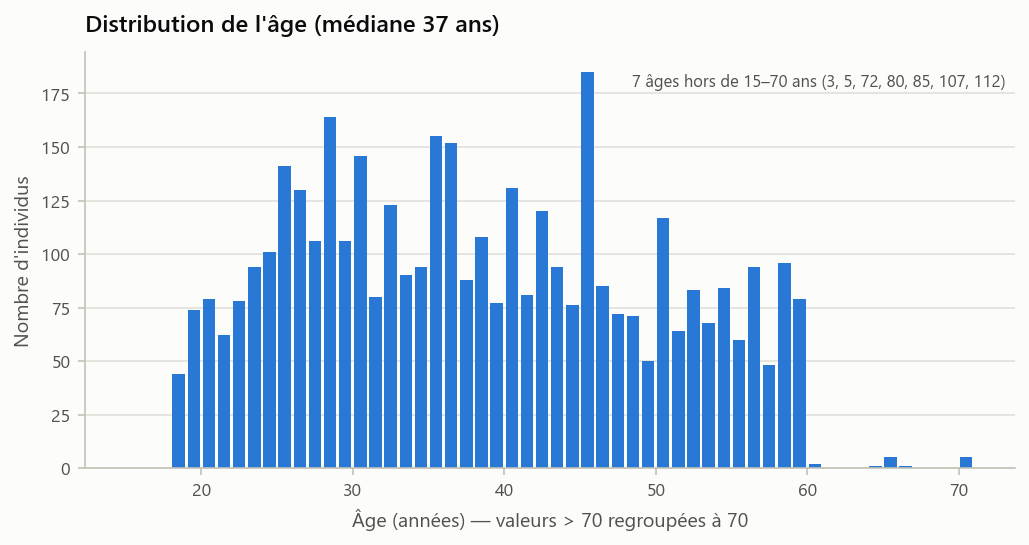

In [11]:
# 6.2 Âge
fig, ax = plt.subplots(figsize=(8, 3.6))
age = brut["age"].dropna()
ax.hist(age.clip(upper=70), bins=np.arange(15, 72, 1), color=BLEU, rwidth=0.82)
ax.set_xlabel("Âge (années) — valeurs > 70 regroupées à 70")
ax.set_ylabel("Nombre d'individus")
ax.set_title(f"Distribution de l'âge (médiane {age.median():.0f} ans)")
hors = int(((age < 15) | (age > 70)).sum())
ax.text(0.99, 0.95, f"{hors} âges hors de 15–70 ans (3, 5, 72, 80, 85, 107, 112)",
        transform=ax.transAxes, ha="right", va="top", fontsize=8, color=C["encre2"])
o.sauver_figure(fig, RES, "distribution_age");

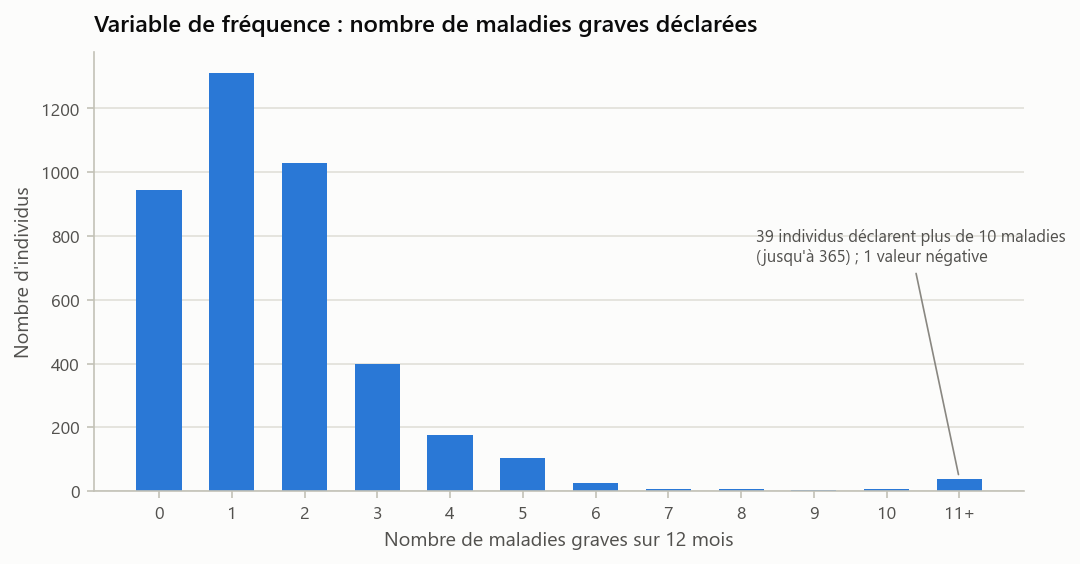

In [12]:
# 6.3 Nombre de maladies graves (variable de fréquence)
nm = brut["nb_maladies_graves"].dropna()
classes = list(range(0, 11)) + ["11+"]
eff = [int((nm == k).sum()) for k in range(0, 11)] + [int((nm > 10).sum())]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([str(k) for k in classes], eff, color=BLEU, width=0.62)
ax.set_xlabel("Nombre de maladies graves sur 12 mois")
ax.set_ylabel("Nombre d'individus")
ax.set_title("Variable de fréquence : nombre de maladies graves déclarées")
ax.annotate(f"{eff[-1]} individus déclarent plus de 10 maladies\n(jusqu'à 365) ; 1 valeur négative",
            xy=(11, eff[-1]), xytext=(8.2, max(eff) * 0.55), fontsize=8, color=C["encre2"],
            arrowprops=dict(arrowstyle="-", color=C["attenue"], lw=0.8))
o.sauver_figure(fig, RES, "distribution_nb_maladies_graves");

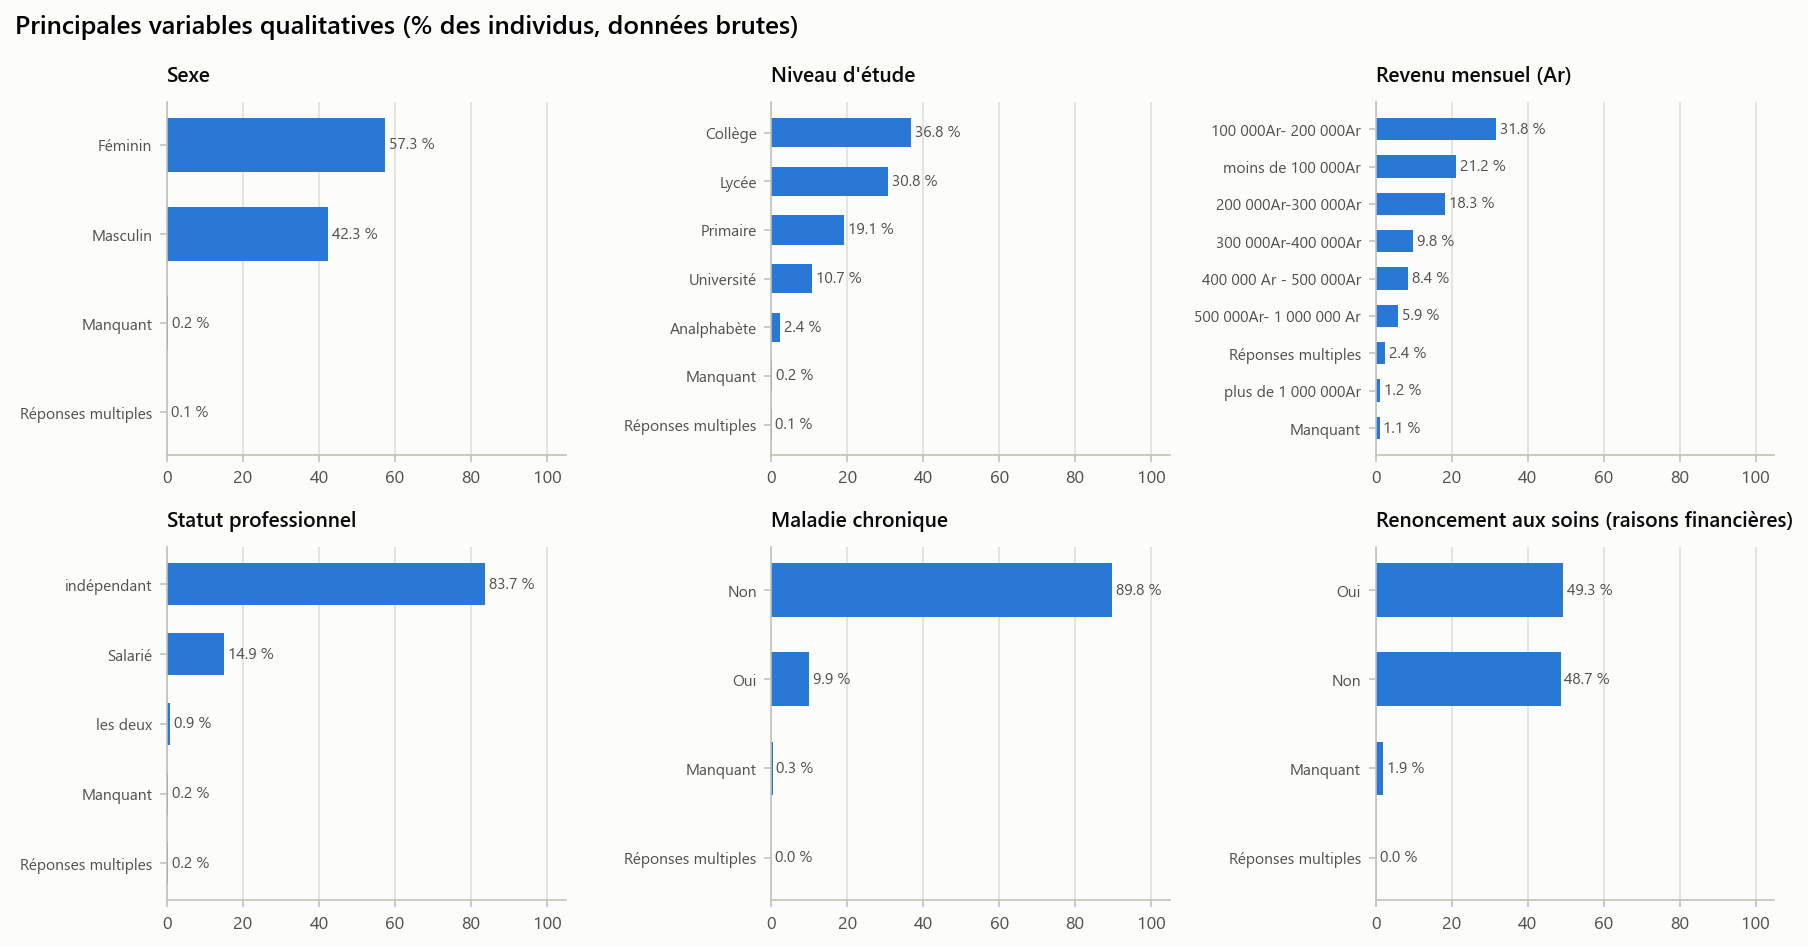

In [13]:
# 6.4 Principales variables qualitatives (petits multiples, une couleur)
def libelle_court(v: str) -> str:
    v = re.sub(r"^\d+\.\s*", "", " ".join(str(v).split()))
    v = re.sub(r"\s*\([^)]*\)", "", v)
    return v[:28]


choix = [("sexe", "Sexe"), ("niveau_etude", "Niveau d'étude"), ("revenu", "Revenu mensuel (Ar)"),
         ("statut_pro", "Statut professionnel"), ("maladie_chronique", "Maladie chronique"),
         ("renoncement_soins", "Renoncement aux soins (raisons financières)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (c, titre) in zip(axes.ravel(), choix):
    resolu, multiples = o.premiere_modalite(brut[c])
    s = resolu.map(lambda v: np.nan if v is None else libelle_court(v))
    s[multiples] = "Réponses multiples"
    vc = s.value_counts(dropna=False)
    vc.index = vc.index.map(lambda v: "Manquant" if pd.isna(v) else v)
    vc = vc.sort_values()
    ax.barh(vc.index, 100 * vc.values / n, color=BLEU, height=0.6)
    for y, val in enumerate(100 * vc.values / n):
        ax.text(val + 1, y, f"{val:.1f} %", va="center", fontsize=7.5, color=C["encre2"])
    ax.set_xlim(0, 105)
    ax.set_title(titre, fontsize=10)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=7.5)
fig.suptitle("Principales variables qualitatives (% des individus, données brutes)", x=0.01,
             ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "variables_qualitatives_principales");

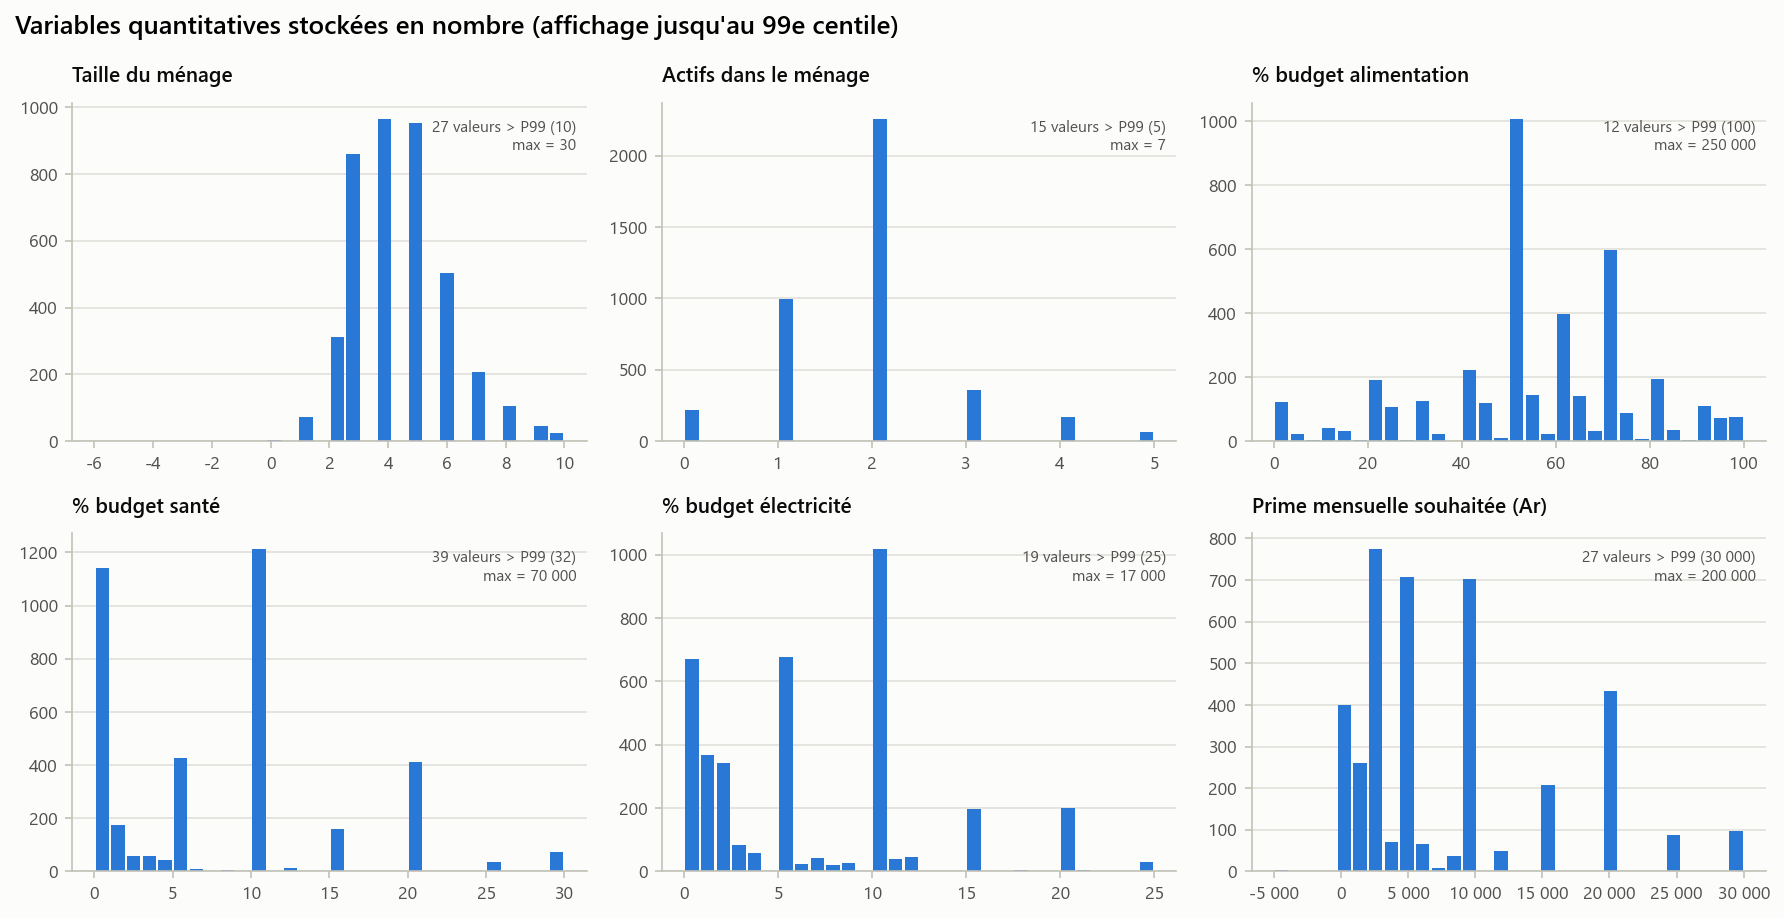


## Fichiers produits

- partie1_donnees\1.0_presentation\resultats\figures\distribution_age.png
- partie1_donnees\1.0_presentation\resultats\figures\distribution_nb_maladies_graves.png
- partie1_donnees\1.0_presentation\resultats\figures\manquants_par_variable.png
- partie1_donnees\1.0_presentation\resultats\figures\variables_qualitatives_principales.png
- partie1_donnees\1.0_presentation\resultats\figures\variables_quantitatives.png
- partie1_donnees\1.0_presentation\resultats\journal.txt
- partie1_donnees\1.0_presentation\resultats\tables\dictionnaire_variables.csv
- partie1_donnees\1.0_presentation\resultats\tables\distribution_nb_maladies_graves.csv
- partie1_donnees\1.0_presentation\resultats\tables\frequences_qualitatives.csv
- partie1_donnees\1.0_presentation\resultats\tables\quantitatives_saisies_en_texte.csv
- partie1_donnees\1.0_presentation\resultats\tables\resume_qualitatives.csv
- partie1_donnees\1.0_presentation\resultats\tables\stats_quantitatives.csv
- partie1_donnees\

In [14]:
# 6.5 Variables quantitatives (histogrammes, affichage limité au 99e centile)
choix = [("taille_menage", "Taille du ménage"), ("nb_actifs_menage", "Actifs dans le ménage"),
         ("budget_alim", "% budget alimentation"), ("budget_sante", "% budget santé"),
         ("budget_elec", "% budget électricité"), ("prime_souhaitee", "Prime mensuelle souhaitée (Ar)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, (c, titre) in zip(axes.ravel(), choix):
    s = brut[c].dropna()
    p99 = s.quantile(0.99)
    ax.hist(s[s <= p99], bins=30, color=BLEU, rwidth=0.85)
    ax.set_title(titre, fontsize=10)
    ax.text(0.98, 0.95, f"{int((s > p99).sum())} valeurs > P99 ({p99:,.0f})\nmax = {s.max():,.0f}"
            .replace(",", " "), transform=ax.transAxes, ha="right", va="top", fontsize=7.5,
            color=C["encre2"])
    ax.xaxis.set_major_formatter(o.format_milliers)
fig.suptitle("Variables quantitatives stockées en nombre (affichage jusqu'au 99e centile)",
             x=0.01, ha="left")
fig.tight_layout()
o.sauver_figure(fig, RES, "variables_quantitatives")

log.section("Fichiers produits")
for f in sorted(RES.rglob("*.*")):
    log("-", f.relative_to(o.RACINE))
log.fermer();

---

Les tableaux complets sont dans `resultats/tables/`, les figures dans `resultats/figures/` et la sortie intégrale dans `resultats/journal.txt`. Commentaires et décisions : [README.md](README.md).